# ML ASSIGNMENT - B2

Classify the email using the binary classification method. Email Spam detection has two states:

a) Normal State(0) - Not Spam<br>
b) Abnormal State(1) - Spam. 

Use K-Nearest Neighbors and Support Vector Machine for classification.<br>
Analyze their performance. 

<b>Dataset link: Email Spam Classification Dataset (Kaggle)</b><br>
https://www.kaggle.com/datasets/balaka18/email-spam-classification-dataset-csv 

### 1) Import libraries

In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

### 2) Load Dataset

In [114]:
df = pd.read_csv("emails.csv")

In [115]:
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [116]:
df.shape

(5172, 3002)

In [117]:
print("\nMissing Values:")
print(df.isnull().sum().sum())


Missing Values:
0


In [118]:
print("\nSpam Distribution:")
print(df['Prediction'].value_counts())


Spam Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


<b>Visualize spam distribution</b>

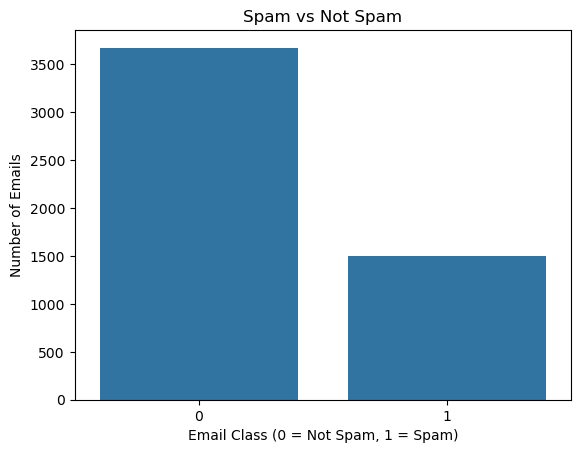

In [119]:
sns.countplot(x='Prediction', data=df)
plt.title("Spam vs Not Spam")
plt.xlabel("Email Class (0 = Not Spam, 1 = Spam)")
plt.ylabel("Number of Emails")
plt.show()

### 3) Preprocessing

Remove the email identifier column

In [120]:
# Remove Email No. column
df = df.drop(columns=['Email No.'])

### 4) Select features and split the dataset (80:20)

In [121]:
# Separate features and target
X = df.drop('Prediction', axis=1)
y = df['Prediction']

In [122]:
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5172, 3000)
Target Shape: (5172,)


In [123]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

### 5) Feature Scaling

In [124]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### 6) Implement K-Nearest Neighbors (KNN

We use K = 5

In [125]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Accuracy:", np.round(accuracy_score(y_test, y_pred_knn), 2))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.85

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.80      0.88       739
           1       0.66      0.95      0.78       296

    accuracy                           0.85      1035
   macro avg       0.82      0.88      0.83      1035
weighted avg       0.89      0.85      0.85      1035



In [126]:
# Predict
y_pred_knn

array([0, 0, 1, ..., 0, 1, 0], shape=(1035,))

### 7) Implement Support Vector Machine (SVM)

We use a linear kernel for simple classification.

In [127]:
svm = SVC(kernel='linear')

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("SVM Accuracy:", np.round(accuracy_score(y_test, y_pred_svm), 2))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.95

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.96       739
           1       0.90      0.92      0.91       296

    accuracy                           0.95      1035
   macro avg       0.93      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



In [128]:
# Predict
y_pred_svm

array([0, 0, 1, ..., 0, 1, 0], shape=(1035,))

### 8) Confusion matrices
Visualize the performance of both models.

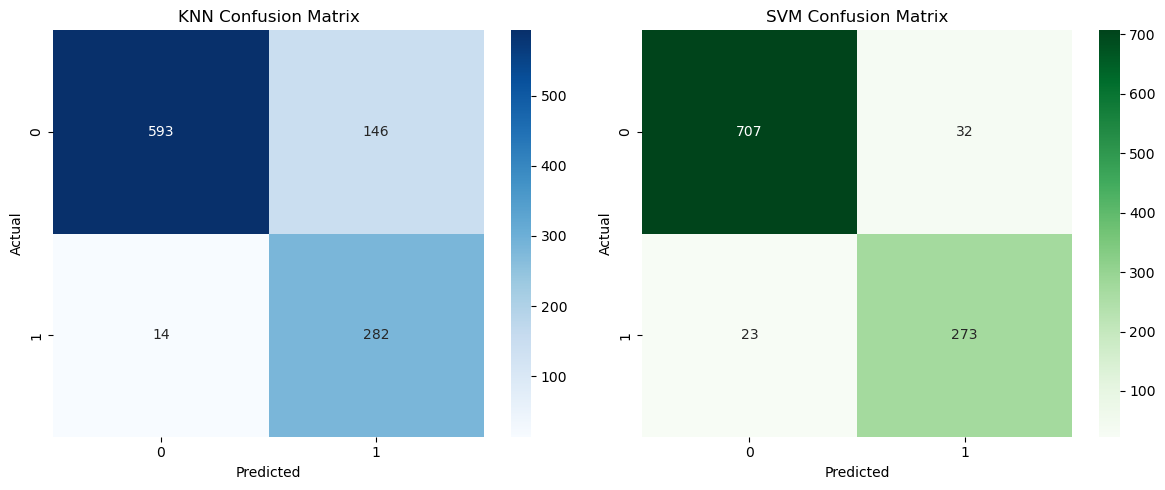

In [129]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# KNN Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# SVM Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

### 9) Compare model performance
Compare accuracy, precision, recall and F1-score.

In [130]:
results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Precision': [
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_svm)
    ],
    'Recall': [
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_svm)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_svm)
    ]
})

results.round(2)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.85,0.66,0.95,0.78
1,SVM,0.95,0.90,0.92,0.91


In [131]:
best_model = results.loc[results['F1 Score'].idxmax()]
print("Best Model:", best_model['Model'])

Best Model: SVM
